# Loading the Dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = "amz_uk_price_prediction_dataset.csv"
amazon_df = pd.read_csv(data, encoding='ISO-8859-1')

# Initial Exploration

In [5]:
amazon_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
amazon_df.shape

(2443651, 9)

In [7]:
amazon_df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [8]:
amazon_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


# Exploring numerical and categorical variables

#### 1. Retrivieng the unique data types

In [9]:
list(set(amazon_df.dtypes.tolist()))

[dtype('float64'), dtype('bool'), dtype('int64'), dtype('O')]

#### 2. Extracting column names with numerical data types

In [10]:
amazon_df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

#### 3. Counting and sorting the unique values for each numerical column

In [11]:
amazon_df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

# Part 1:

#### 1.1 Crosstab Analysis: 

In [12]:
crosstab_result = pd.crosstab(amazon_df['category'], amazon_df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [13]:
best_seller_rate = (crosstab_result[True] / crosstab_result.sum(axis=1)).sort_values(ascending=False)

print(best_seller_rate)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
                                    ...   
Bedding Collections               0.000000
CPUs                              0.000000
CD, Disc & Tape Players           0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Length: 296, dtype: float64


Categories can differ meaningfully in best-seller prevalence.

#### 1.2 Statistical Tests: 

In [16]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(crosstab_result)

chi2, p_value, dof


(np.float64(36540.20270061387), np.float64(0.0), 295)

There is strong statistical evidence that the distribution of best-sellers depends on product category. This aligns with the earlier observation that best-seller proportions vary substantially across categories, including many with zero best-sellers.

In [18]:
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

0.1222829439760564

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


A value of 0.122 indicates a weak association between product category and best-seller status.

#### 3. Visualizations:

In [20]:
crosstab_prop = pd.crosstab(
    amazon_df['category'],
    amazon_df['isBestSeller'],
    normalize='index'
)
crosstab_prop.columns = ['Not Best-Seller', 'Best-Seller']
top_categories = (
    crosstab_prop['Best-Seller']
    .sort_values(ascending=False)
    .head(20)
    .index
)
plot_data = crosstab_prop.loc[top_categories]

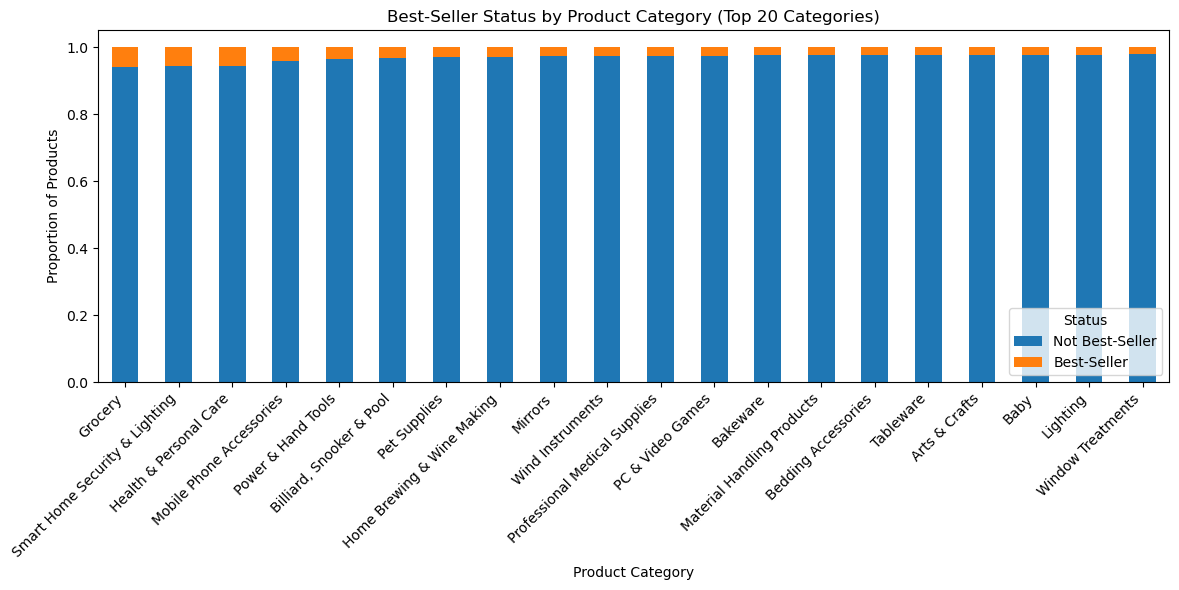

In [22]:
import matplotlib.pyplot as plt

plot_data.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Best-Seller Status by Product Category (Top 20 Categories)')
plt.ylabel('Proportion of Products')
plt.xlabel('Product Category')
plt.legend(title='Status', loc='lower right')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Part 2 Exploring Product Prices and Ratings Across Categories and Brands

**Preliminary Step: Remove outliers in product prices.**

In [24]:
Q1 = amazon_df['price'].quantile(0.25)
Q3 = amazon_df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [27]:
df_no_outliers = amazon_df[
    (amazon_df['price'] >= lower_bound) &
    (amazon_df['price'] <= upper_bound)
]

#### 1. Violin Plots

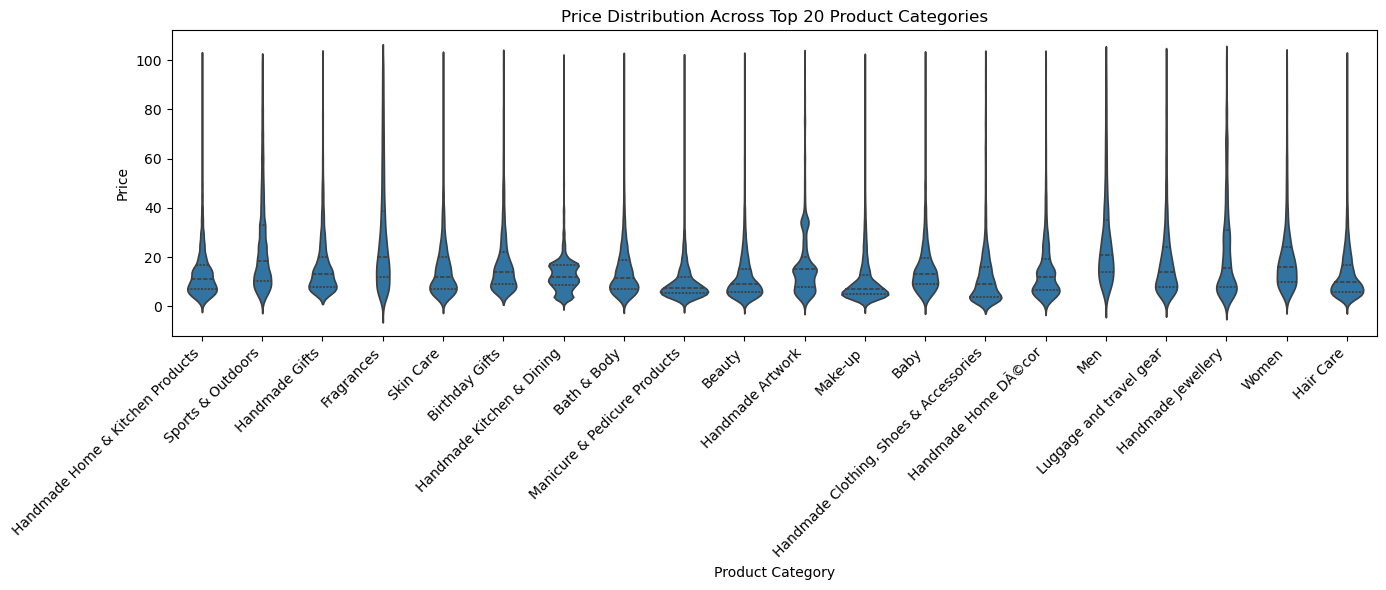

In [28]:
top_20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

plot_df = df_no_outliers[
    df_no_outliers['category'].isin(top_20_categories)
]

plt.figure(figsize=(14, 6))
sns.violinplot(
    data=plot_df,
    x='category',
    y='price',
    inner='quartile'
)

plt.title('Price Distribution Across Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [29]:
median_price_by_category = (
    df_no_outliers
    .groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

Category with highest median price are Desktop PCs

#### 2. Bar Charts:

In [36]:
top_10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

avg_price_top_10 = (
    df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

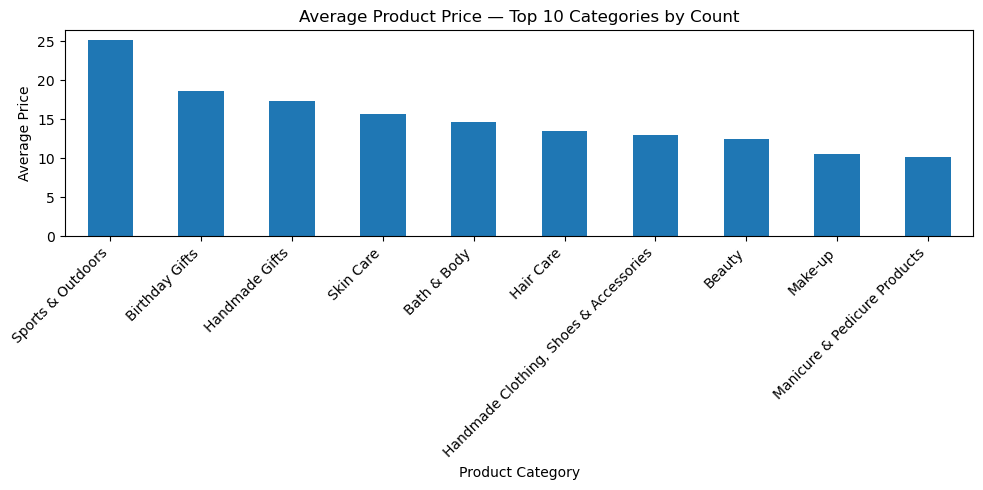

In [37]:
plt.figure(figsize=(10, 5))
avg_price_top_10.plot(kind='bar')
plt.title('Average Product Price — Top 10 Categories by Count')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [33]:
avg_price_all = (
    df_no_outliers
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

avg_price_all.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

#### Bar Plots:

In [38]:
rating_plot_df = df_no_outliers[
    df_no_outliers['category'].isin(top_10_categories)
]

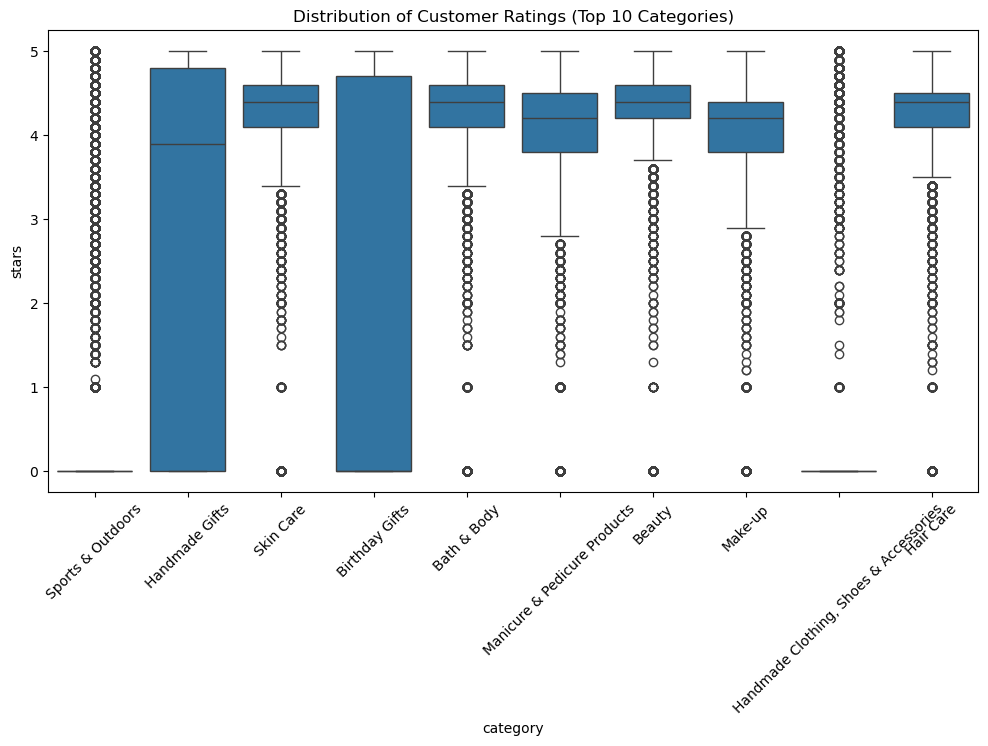

In [42]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=rating_plot_df)
plt.xticks(rotation=45)
plt.title('Distribution of Customer Ratings (Top 10 Categories)')
plt.show()

# Part 3 Investigating the Interplay Between Product Prices and Ratings

#### 1. Correlation Coefficients:

In [47]:
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
correlation

np.float64(-0.07767299878181352)

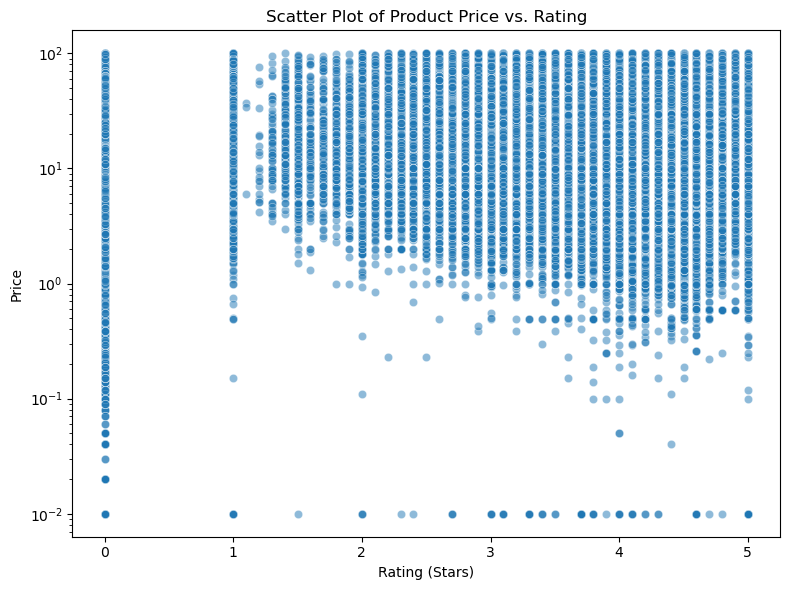

In [48]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_no_outliers,
    x='stars',
    y='price',
    alpha=0.5
)
plt.yscale('log')  # Optional: log scale for price to reduce skew
plt.title('Scatter Plot of Product Price vs. Rating')
plt.xlabel('Rating (Stars)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

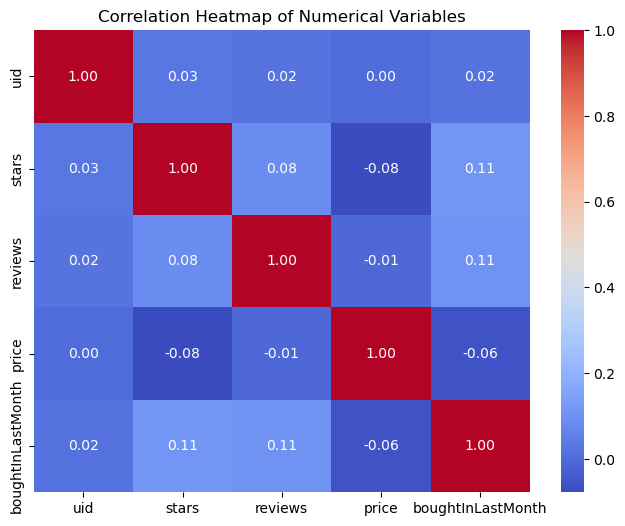

In [49]:
numerical_cols = df_no_outliers.select_dtypes(include='number')

plt.figure(figsize=(8, 6))
sns.heatmap(
    numerical_cols.corr(),
    annot=True,
    fmt=".2f",
    cmap='coolwarm'
)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

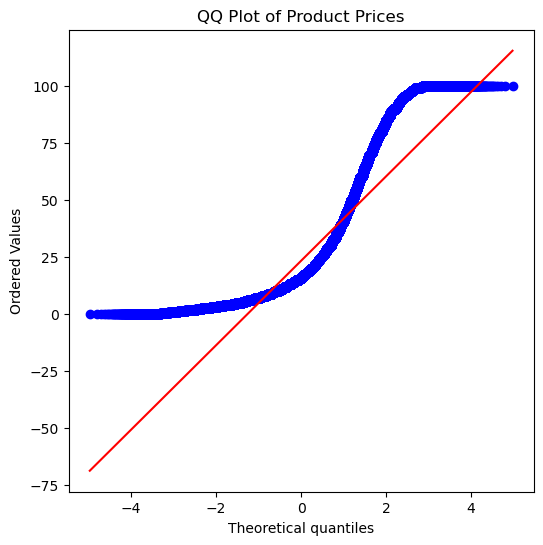

In [51]:
import scipy.stats as stats

plt.figure(figsize=(6, 6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices')
plt.show()